# EOF analysis of Spatiotemporal Dataset

**This is a similar example but uses another Python EOF package.**

**Python EOF package**: The EOF package that we will use is from Dawson (http://ajdawson.github.io/eofs/) and is already installed in our environment.

## 1. Load basic libraries

In [11]:
import importlib
import pandas as pd
import xarray as xr
import numpy as np
from numpy import nan
import sys
import warnings
import math
from glob import glob
import matplotlib.pyplot as plt

from scipy import signal
import numpy.polynomial.polynomial as poly
from netCDF4 import Dataset

import matplotlib.pyplot as plt
from eofs.standard import Eof

## 2. Read SST Data

In [14]:
url = 'http://www.esrl.noaa.gov/psd/thredds/dodsC/Datasets/noaa.ersst.v5/sst.mnmean.nc'
ds = xr.open_dataset(url, drop_variables=['time_bnds'])
ds = ds.sel(time=slice('1982', '2016'))
ds

<xarray.Dataset> Size: 27MB
Dimensions:  (time: 420, lat: 89, lon: 180)
Coordinates:
  * time     (time) datetime64[ns] 3kB 1982-01-01 1982-02-01 ... 2016-12-01
  * lat      (lat) float32 356B 88.0 86.0 84.0 82.0 ... -82.0 -84.0 -86.0 -88.0
  * lon      (lon) float32 720B 0.0 2.0 4.0 6.0 8.0 ... 352.0 354.0 356.0 358.0
Data variables:
    sst      (time, lat, lon) float32 27MB ...
Attributes: (12/39)
    climatology:                     Climatology is based on 1971-2000 SST, X...
    description:                     In situ data: ICOADS2.5 before 2007 and ...
    keywords_vocabulary:             NASA Global Change Master Directory (GCM...
    keywords:                        Earth Science > Oceans > Ocean Temperatu...
    instrument:                      Conventional thermometers
    source_comment:                  SSTs were observed by conventional therm...
    ...                              ...
    comment:                         SSTs were observed by conventional therm...
    summary:                         ERSST.v5 is developed based on v4 after ...
    dataset_title:                   NOAA Extended Reconstructed SST V5
    _NCProperties:                   version=2,netcdf=4.6.3,hdf5=1.10.5
    data_modified:                   2026-11-03
    DODS_EXTRA.Unlimited_Dimension:  time

In [15]:
lons = ds.lon
lats = ds.lat
sst = ds.sst

nt, nlat, nlon = sst.shape
ngrd = nlon*nlat

## 3. Detrend and remove seasonal cycle 

Before carrying out EOF analysis, we need to remove the linear trend of the SST data as well as the seasonal cycle.

### 3.1 Detrend the data

Here we use the `detrend` function from [`scipy.signal`]('https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.detrend.html'). The basic syntax is `detrend(data, axis, type='linear')` with `axis` denoting the axis along which to detrend the data. However, the `detrend` function can't deal with NaNs so some additional data processing needs to be applied (see code below).

We could also use `polyfit` or `stats.linregress` to calculate the linear trend first and subtract the linear trend from the data.

In [16]:
nan_ind = np.isnan(ds.sst.values)

sstf = xr.where(np.isnan(ds.sst.values), 1000, ds.sst.values)  #  fill nan with 1000

sstf = sstf.reshape((nt,nlat*nlon), order='F')
sstf_detrend = signal.detrend(sstf, axis=0, type='linear', bp=0)  #  detrend the data on the time dimension 

sstf_detrend = sstf_detrend.reshape((nt,nlat,nlon), order='F')

sstf_detrend[nan_ind] = nan  #  fill in nan

sstf_detrend = sstf_detrend.reshape((12,int(nt/12),nlat,nlon), order='F').transpose((1,0,2,3))

sst_detrend = sstf_detrend

sst_detrend.shape

(35, 12, 89, 180)

In [13]:
## make plots of intermediate results 

# fig, ax = plt.subplots(nrows=1)
# im = ax.pcolormesh(ds.lon, ds.lat, sst_detrend[10,6,:,:])
# fig.colorbar(im)

### 3.2 Calculate and remove seasonal cycle

In [17]:
sst_season = np.mean(sst_detrend, axis=0)
sst_anom = sst_detrend - sst_season
sst_anom = sst_anom.transpose((1,0,2,3)).reshape((nt,nlat,nlon), order='F')
sst_anom.shape

(420, 89, 180)

## 4. Carry out EOF analysis

### 4.1 Create an EOF solver to do the EOF analysis

Square-root of cosine of latitude weights are applied before the computation of EOFs.

In [18]:
wgts = np.cos(np.deg2rad(lats))
wgts = np.sqrt(wgts)
wgts = np.tile(wgts,(nt,nlon,1)).transpose((0,2,1))
wgts.shape

(420, 89, 180)

In [19]:
solver = Eof(sst_anom, weights=wgts)

### 4.2 Retrieve the leading EOFs

Returns EOFs, principal component time series (PCs), fractions of the total variance accounted for by each EOF, and eigenvalues (decreasing variances) associated with each EOF.

In [20]:
eof1 = solver.eofs(neofs=10)
pc1  = solver.pcs(npcs=10, pcscaling=0)
varfrac = solver.varianceFraction()
lambdas = solver.eigenvalues()

pc1.shape

(420, 10)

## 5. Visualize leading EOFs

### 5.1 Plot EOFs and PCs

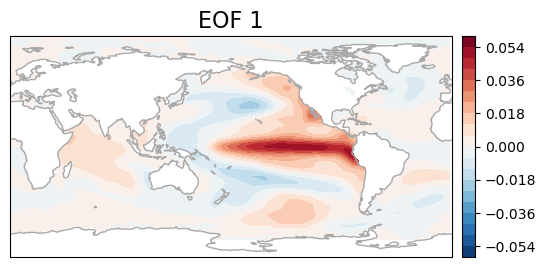

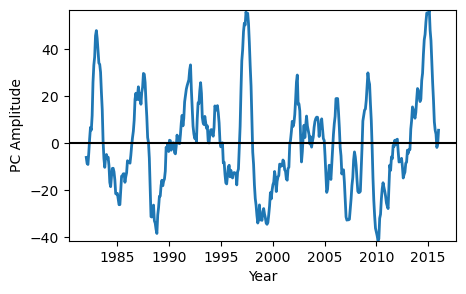

In [21]:
import matplotlib.pyplot as plt; import matplotlib
import cartopy.crs as ccrs
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
import datetime as dt

for i in range(0,1):
    # fig = plt.figure(figsize=(4,3))
    # plt.subplot(211)

    fig = plt.figure(figsize=(6,4))
    m = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
    clevs = np.linspace(-0.06, 0.06, 21)
    cs = m.contourf(lons, lats, eof1[i,:,:].squeeze(), clevs, cmap=plt.cm.RdBu_r, transform=ccrs.PlateCarree())   
    m.coastlines(color='darkgray', linewidth=1)
    m.set_extent([-180, 180, -90, 90],crs=ccrs.PlateCarree())
    m.set_title('EOF ' + str(i+1), fontsize=16)
    cax = make_axes_locatable(m).append_axes("right", size="3%", pad=0.1, axes_class=plt.Axes)
    cbar = plt.colorbar(cs, cax=cax, orientation='vertical') 

    # plt.subplot(212)
    fig = plt.figure(figsize=(5,3))
    days = np.linspace(1982,2016,nt)
    plt.plot(days, pc1[:,i], linewidth=2)
    plt.axhline(0, color='k')
    plt.xlabel('Year')
    plt.ylabel('PC Amplitude')   
    plt.ylim(np.min(pc1.squeeze()), np.max(pc1.squeeze()))  

The spatial pattern of EOF1 is the canonical El Nino pattern, and the associated time series shows large peaks and troughs for well-known El Nino and La Nina events.

### 5.2 Check variances explained by leading EOFs

(5.100763586938432e-16, 0.21645955741405487)

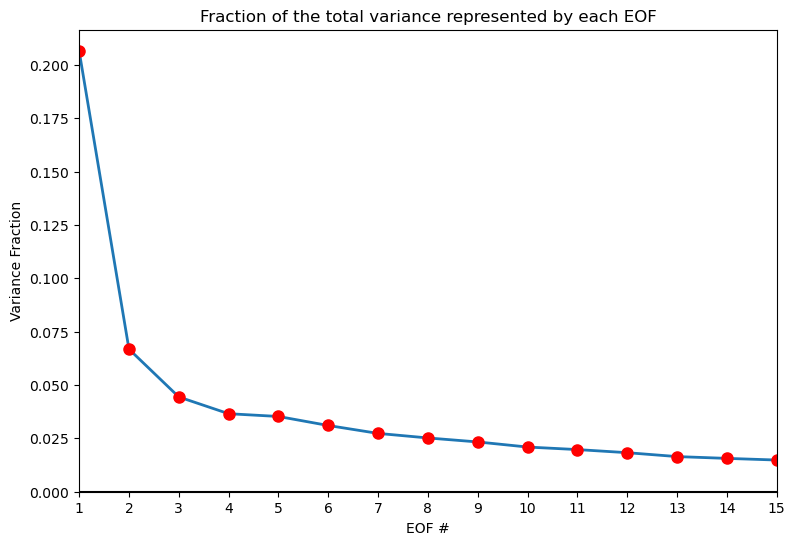

In [22]:
plt.figure(figsize=(9,6))
eof_num = range(1, 16)
plt.plot(eof_num, varfrac[0:15], linewidth=2)
plt.plot(eof_num, varfrac[0:15], linestyle='None', marker="o", color='r', markersize=8)
plt.axhline(0, color='k')
plt.xticks(range(1, 16))
plt.title('Fraction of the total variance represented by each EOF')
plt.xlabel('EOF #')
plt.ylabel('Variance Fraction')
plt.xlim(1, 15)
plt.ylim(np.min(varfrac), np.max(varfrac)+0.01)

## References

http://unidata.github.io/netcdf4-python/

John D. Hunter. Matplotlib: A 2D Graphics Environment, Computing in Science & Engineering, 9, 90-95 (2007), DOI:10.1109/MCSE.2007.55

Stéfan van der Walt, S. Chris Colbert and Gaël Varoquaux. The NumPy Array: A Structure for Efficient Numerical Computation, Computing in Science & Engineering, 13, 22-30 (2011), DOI:10.1109/MCSE.2011.37

Kalnay et al.,The NCEP/NCAR 40-year reanalysis project, Bull. Amer. Meteor. Soc., 77, 437-470, 1996.